# Forecast and evaluation Monte Carlo precision

**Research question.** Which numerical quantities change when the number of simulated future years increases?

Historical observations and fitted parameters remain fixed. Forecast-count comparisons occur before evaluation; evaluation-count comparisons use frozen weights. The pilot grid is 10000/20000 forecast and 25000/50000 evaluation paths; smoke uses smaller counts.

This recipe runs independently in the installed project environment. The default is a labelled smoke experiment; set `THESIS_PROFILE=pilot` before starting the kernel for the configured pilot counts. Source functions are reusable and directly linked below. Outputs report actual calculations, not assumed findings.

### Load the numerical experiment

These scenario counts describe future years, not historical sample size.

**Inputs:** profile and configuration.  
**Created / outputs:** cfg and helpers.  
**Canonical implementation:** `annual.studies`.

In [1]:
# M5.CONVERGENCE.SETUP — Load the numerical experiment
# Inputs: profile and configuration
# Created: cfg and helpers
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import PublicSpec, load_run_config, oracle_state, project_root, stream
from thesis_portfolio.annual.simulation import generate_history, simulate_conditional_paths, oracle_continue
from thesis_portfolio.annual.estimation import fit_market_model
from thesis_portfolio.annual.portfolio import annual_moments, freeze_portfolios, evaluate_portfolios
from thesis_portfolio.optimization import equal_risk_contribution, markowitz, cvar, risk_contributions
from thesis_portfolio.annual.diagnostics import mathematical_backstops, residual_diagnostics, parameter_comparison, recurrence_report
from thesis_portfolio.annual.experiment import execution_profile, begin_run, save_run
from thesis_portfolio.annual import visualization as plots
from thesis_portfolio.annual.studies import convergence_study, study_directory, save_study
root=project_root(os.environ.get('THESIS_PROJECT_ROOT'))
cfg=execution_profile(load_run_config(root/'configs/annual/pilot.yaml'),os.environ.get('THESIS_PROFILE','smoke'))


### Declare count grids before evaluation

The largest forecast count is prespecified; oracle performance does not select the portfolio or count.

**Inputs:** run profile.  
**Created / outputs:** forecast_counts, evaluation_counts.  
**Canonical implementation:** `annual.studies.convergence_study`.

In [2]:
# M5.CONVERGENCE.COUNTS — Declare count grids before evaluation
# Inputs: run profile
# Created: forecast_counts, evaluation_counts
forecast_counts = (500,1000) if cfg['status']=='smoke' else (10000,20000)
evaluation_counts = (1000,2000) if cfg['status']=='smoke' else (25000,50000)
print(forecast_counts,evaluation_counts)


(10000, 20000) (25000, 50000)


### Run the two distinct count checks

The orchestrator freezes the fitted market, constructs nested forecast scenarios, optimizes before evaluation, and evaluates fixed selected weights on nested oracle scenarios.

**Inputs:** cfg and count grids.  
**Created / outputs:** forecast_table, evaluation_table.  
**Canonical implementation:** `annual.studies.convergence_study`.

In [3]:
# M5.CONVERGENCE.RUN — Run the two distinct count checks
# Inputs: cfg and count grids
# Created: forecast_table, evaluation_table
forecast_table,evaluation_table=convergence_study(cfg,'garch',forecast_counts,evaluation_counts)


### Inspect forecast count sensitivity

Changing forecast scenarios changes estimated annual moments and therefore can change r_star. Show target changes with allocations.

**Inputs:** forecast_table.  
**Created / outputs:** forecast evidence.  
**Canonical implementation:** `annual.studies.convergence_study`.

In [4]:
# M5.CONVERGENCE.FORECAST — Inspect forecast count sensitivity
# Inputs: forecast_table
# Created: forecast evidence
display(forecast_table)


,phase,count,strategy,target,weight_0,weight_1,weight_2,weight_3,weight_4,status
0,forecast,10000,ERC,-0.021599,0.357820,0.241762,0.181826,0.135564,0.083028,"numerical comparison, not certified adequacy"
1,forecast,10000,Markowitz,-0.021599,0.447722,0.264080,0.163110,0.024256,0.100832,"numerical comparison, not certified adequacy"
2,forecast,10000,CVaR,-0.021599,0.475556,0.229454,0.161856,0.027650,0.105483,"numerical comparison, not certified adequacy"
3,forecast,20000,ERC,-0.021282,0.359517,0.241579,0.181945,0.134461,0.082497,"numerical comparison, not certified adequacy"
4,forecast,20000,Markowitz,-0.021282,0.450460,0.261753,0.164710,0.022525,0.100552,"numerical comparison, not certified adequacy"
5,forecast,20000,CVaR,-0.021282,0.480790,0.231839,0.154520,0.026459,0.106392,"numerical comparison, not certified adequacy"


### Inspect fixed-weight evaluation precision

Intervals quantify exception uncertainty conditional on this history, not uncertainty over fitted histories.

**Inputs:** evaluation_table.  
**Created / outputs:** evaluation evidence.  
**Canonical implementation:** `annual.portfolio.evaluate_portfolios`.

In [5]:
# M5.CONVERGENCE.EVALUATION — Inspect fixed-weight evaluation precision
# Inputs: evaluation_table
# Created: evaluation evidence
display(evaluation_table[['count','strategy','confidence','fitted_target','oracle_mean','oracle_cvar','exception_ci_low','exception_ci_high']])


,count,strategy,confidence,fitted_target,oracle_mean,oracle_cvar,exception_ci_low,exception_ci_high
0,25000,ERC,0.95,-0.021282,0.087318,0.168518,0.005080,0.007037
1,25000,ERC,0.99,-0.021282,0.087318,0.226071,0.000192,0.000735
2,25000,Markowitz,0.95,-0.021282,0.080365,0.165002,0.004676,0.006562
3,25000,Markowitz,0.99,-0.021282,0.080365,0.220261,0.000277,0.000889
4,25000,CVaR,0.95,-0.021282,0.079979,0.164044,0.004456,0.006302
5,25000,CVaR,0.99,-0.021282,0.079979,0.219163,0.000220,0.000787
6,50000,ERC,0.95,-0.021282,0.088162,0.167994,0.005550,0.006949
7,50000,ERC,0.99,-0.021282,0.088162,0.228916,0.000438,0.000903
8,50000,Markowitz,0.95,-0.021282,0.081029,0.164179,0.005116,0.006463
9,50000,Markowitz,0.99,-0.021282,0.081029,0.221592,0.000405,0.000856


### Plot evaluation tail estimates

Changes are empirical count sensitivity, not a promise of monotonic convergence.

**Inputs:** evaluation_table.  
**Created / outputs:** convergence_plot.  
**Canonical implementation:** `annual.studies.convergence_study`.

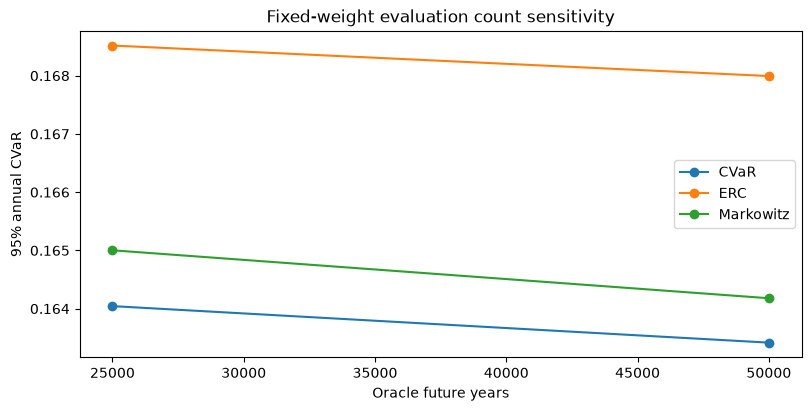

In [6]:
# M5.CONVERGENCE.PLOT — Plot evaluation tail estimates
# Inputs: evaluation_table
# Created: convergence_plot
convergence_plot,ax=plt.subplots(figsize=(8,4),layout='constrained')
for strategy,group in evaluation_table[evaluation_table.confidence==.95].groupby('strategy'):
    ax.plot(group['count'],group.oracle_cvar,marker='o',label=strategy)
ax.set(xlabel='Oracle future years',ylabel='95% annual CVaR',title='Fixed-weight evaluation count sensitivity')
ax.legend()
plt.show()


### Save count-sensitivity evidence

No accepted adequacy threshold is invented from these comparisons.

**Inputs:** tables, count grids.  
**Created / outputs:** study artifacts.  
**Canonical implementation:** `annual.studies.save_study`.

In [7]:
# M5.CONVERGENCE.SAVE — Save count-sensitivity evidence
# Inputs: tables, count grids
# Created: study artifacts
path=study_directory(root,'convergence')
save_study(path,{'forecast':forecast_table,'evaluation':evaluation_table},{'forecast_counts':forecast_counts,'evaluation_counts':evaluation_counts,'adequacy':'not certified'})
convergence_plot.savefig(path/'convergence.png',dpi=150,bbox_inches='tight')
print(path)


/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-convergence-20261127T163516-b9d125a1
